### Import Library

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

### Memuat Data Hasil Pra Pengolahan Data

In [2]:
df = joblib.load('../dataset/step_03_cleaned.pkl')
print("Data berhasil dimuat! Ukuran data:", df.shape)

Data berhasil dimuat! Ukuran data: (4864, 9)


### Membuat Fitur Total Ruangan

In [3]:
df['total_rooms'] = df['bed_rooms'] + df['bath_rooms']

### Membuat Fitur Rasio Bangunan

In [4]:
df['building_ratio'] = df['building_area'] / df['land_area']

### Membuat Fitur Sisa Lahan

In [5]:
df['remaining_land'] = df['land_area'] - df['building_area']

### Membuat Fitur Total Fasilitas

In [6]:
df['total_facilities'] = df['bed_rooms'] + df['bath_rooms'] + df['carport']

### Membuat Fitur Total Luas Properti

In [7]:
df['total_area'] = df['land_area'] + df['building_area']

### Verifikasi Hasil Feature Engineering

In [8]:
df.info()
display(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 4864 entries, 0 to 4863
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   index             4864 non-null   int64  
 1   price             4864 non-null   int64  
 2   district          4864 non-null   str    
 3   city              4864 non-null   str    
 4   bed_rooms         4864 non-null   int64  
 5   bath_rooms        4864 non-null   int64  
 6   carport           4864 non-null   int64  
 7   land_area         4864 non-null   float64
 8   building_area     4864 non-null   float64
 9   total_rooms       4864 non-null   int64  
 10  building_ratio    4864 non-null   float64
 11  remaining_land    4864 non-null   float64
 12  total_facilities  4864 non-null   int64  
 13  total_area        4864 non-null   float64
dtypes: float64(5), int64(7), str(2)
memory usage: 645.1 KB


,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area,total_rooms,building_ratio,remaining_land,total_facilities,total_area
0,2,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0,6,2.250000,-125.0,6,325.0
1,3,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0,6,2.333333,-80.0,6,200.0
2,4,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0,5,2.000000,-60.0,5,180.0
3,5,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0,7,1.928571,-52.0,7,164.0
4,6,2650000000,Tanjung Duren,Jakarta Barat,4,4,0,67.0,149.0,8,2.223881,-82.0,8,216.0


### Analisis Korelasi Fitur Baru

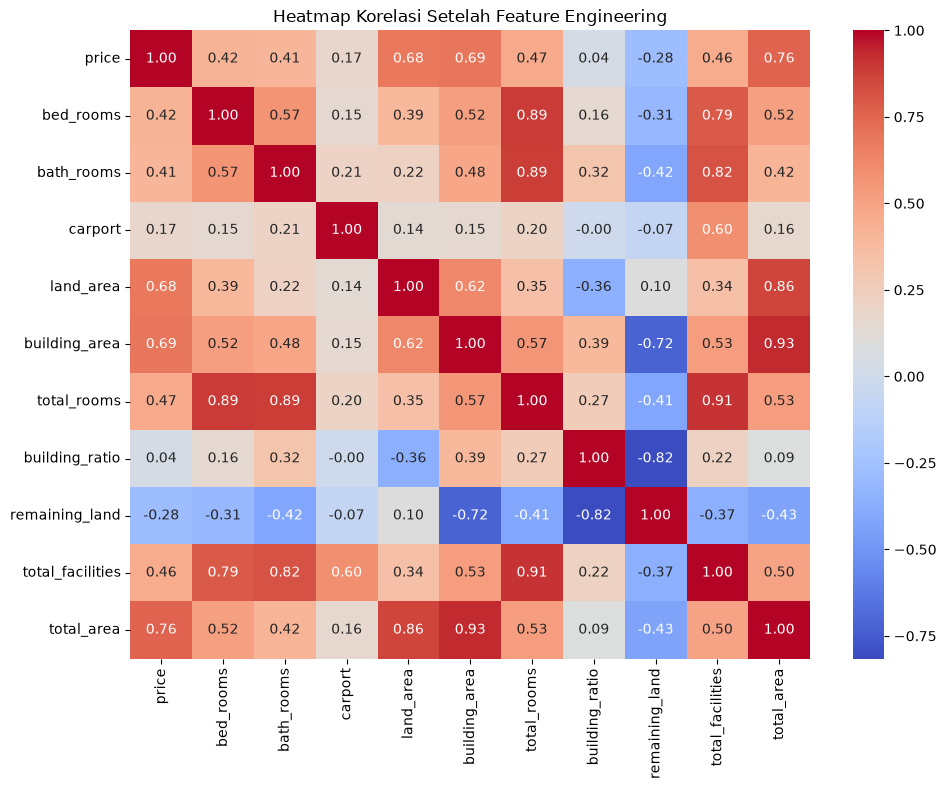

In [9]:
num_cols = [
    'price',
    'bed_rooms',
    'bath_rooms',
    'carport',
    'land_area',
    'building_area',
    'total_rooms',
    'building_ratio',
    'remaining_land',
    'total_facilities',
    'total_area'
]

corr = df[num_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Heatmap Korelasi Setelah Feature Engineering')
plt.tight_layout()
plt.show()

### Korelasi Fitur Terhadap Target (Price)

In [10]:
print("=== Korelasi Fitur Terhadap Price ===")
display(corr['price'].sort_values(ascending=False))

=== Korelasi Fitur Terhadap Price ===


price               1.000000
total_area          0.763250
building_area       0.694260
land_area           0.681938
total_rooms         0.465006
total_facilities    0.455566
bed_rooms           0.418820
bath_rooms          0.405396
carport             0.172786
building_ratio      0.037139
remaining_land     -0.278812
Name: price, dtype: float64

### Menyimpan Data Hasil Feature Engineering

In [11]:
joblib.dump(df, '../dataset/step_04_engineered.pkl')
print("\nData berhasil disimpan ke '../dataset/step_04_engineered.pkl'!")


Data berhasil disimpan ke '../dataset/step_04_engineered.pkl'!
